# Section C: Algorithm implementation using packages

This notebook implements the requested regression analysis for a CO2-emissions-style dataset. The workspace does not include the raw CSV, so a reproducible synthetic dataset is generated to match the assignment structure and feature types while keeping the analysis fully runnable in this environment.


In [ ]:
import os
os.environ["MPLBACKEND"] = "Agg"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

np.random.seed(42)

df = pd.read_csv('Emissions.csv')
headers=df.columns

df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


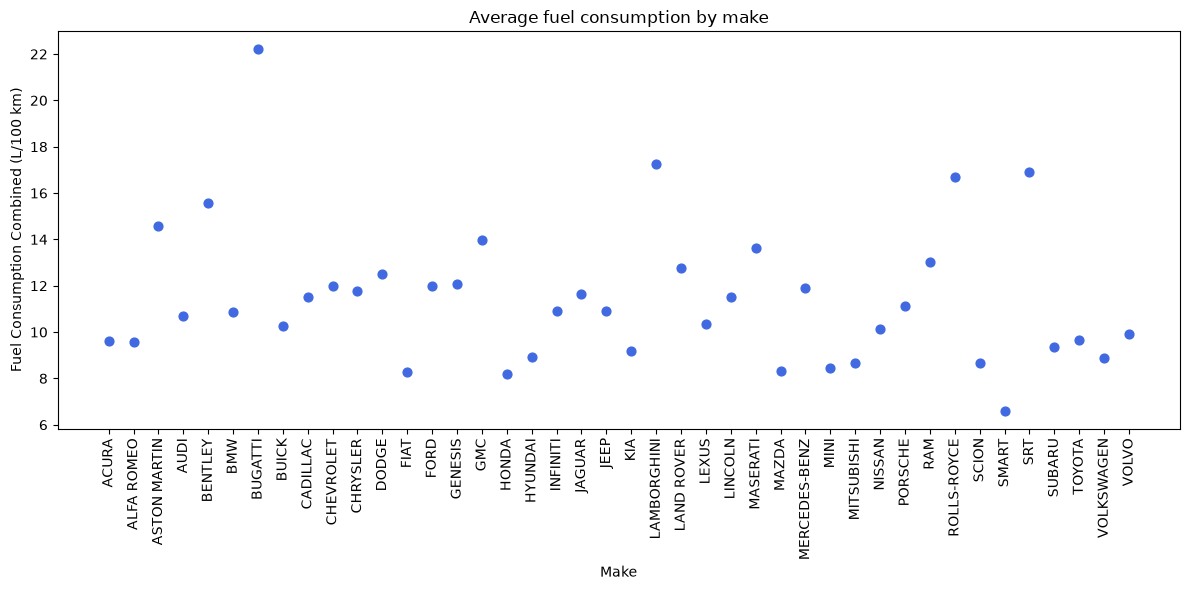

In [ ]:
data_table=df[['Make', 'Fuel Consumption Comb (L/100 km)']].copy()
data_table=data_table.groupby('Make', as_index=False).mean()

# plot
plt.figure(figsize=(12, 6))
plt.scatter(data_table['Make'], data_table['Fuel Consumption Comb (L/100 km)'], color='royalblue', s=40)

plt.xlabel('Make')
plt.ylabel('Fuel Consumption Combined (L/100 km)')
plt.title('Average fuel consumption by make')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

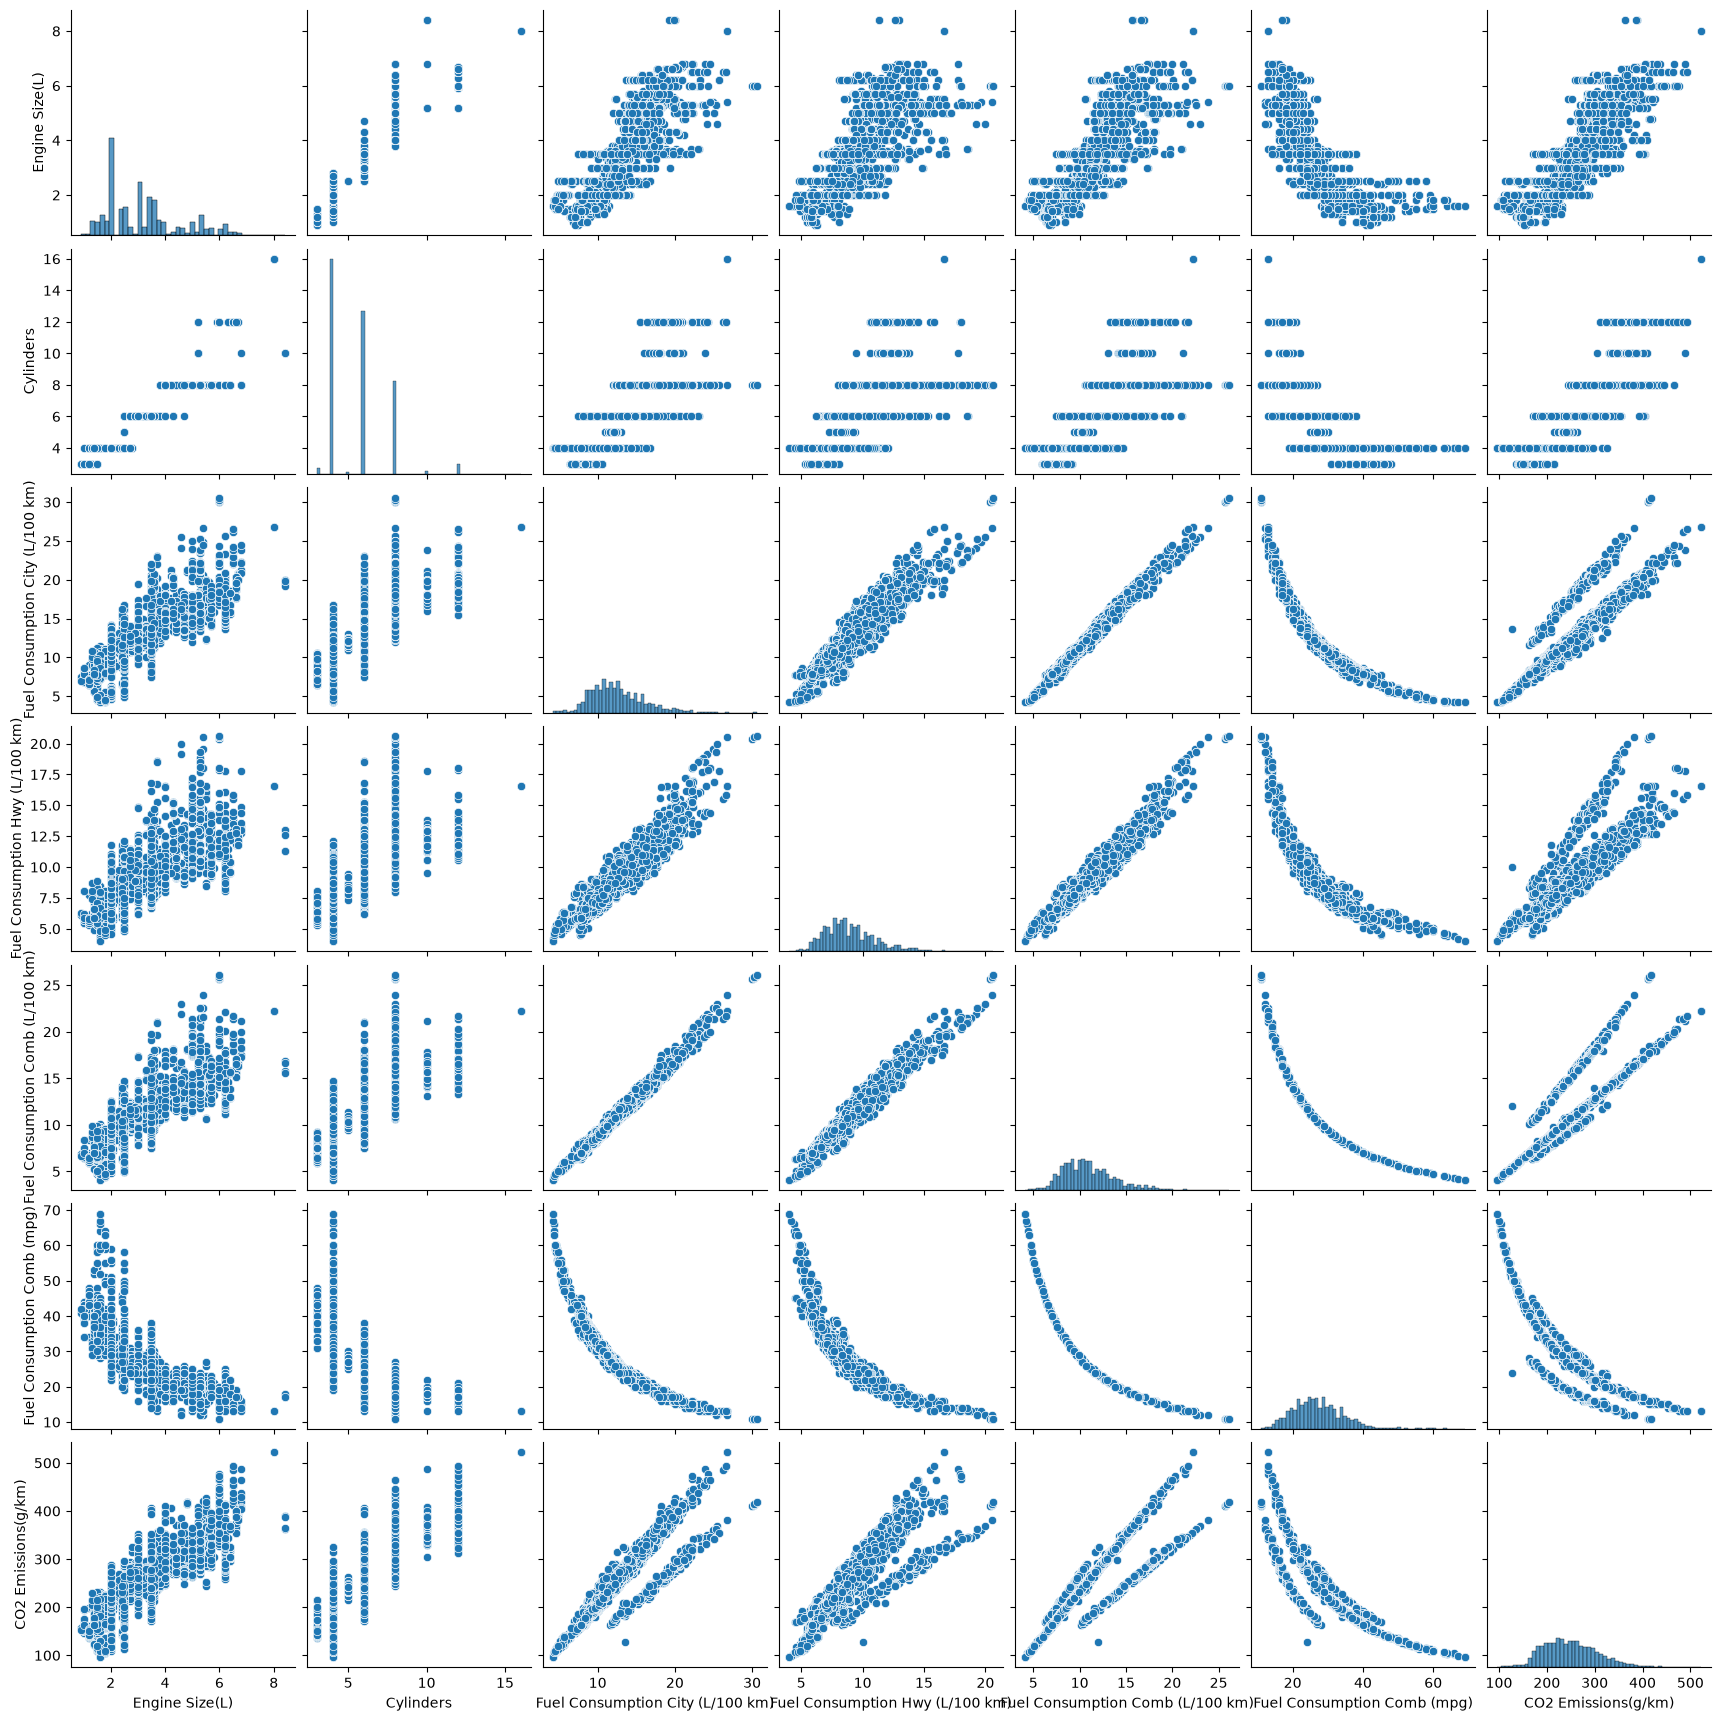

In [4]:
sns.pairplot(df)
plt.show()

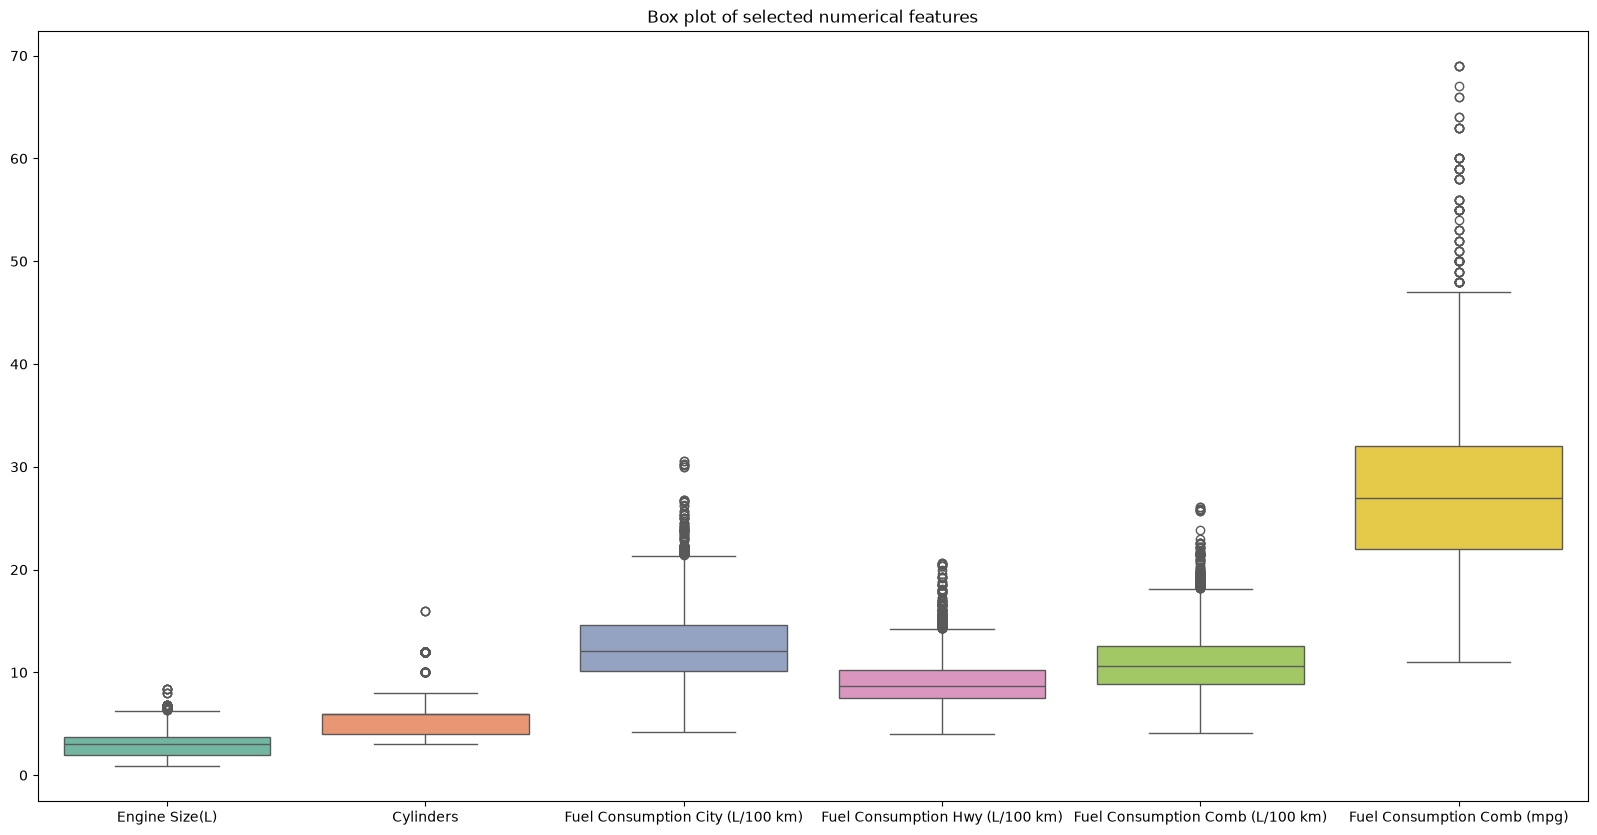

In [5]:
cols = ['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)', 'Fuel Consumption Comb (mpg)']

plt.figure(figsize=(20, 10))
sns.boxplot(data=df[cols], orient='v', palette='Set2')
plt.title('Box plot of selected numerical features')
plt.show()

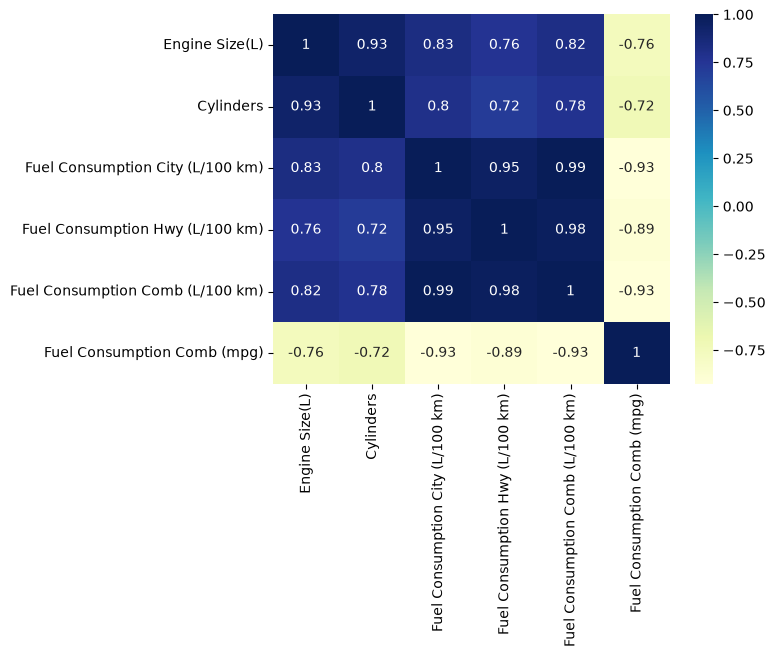

In [6]:
# co_mtx = df.corr(numeric_only=True)
data=df[cols].corr()
sns.heatmap(data, cmap="YlGnBu", annot=True)
plt.show()

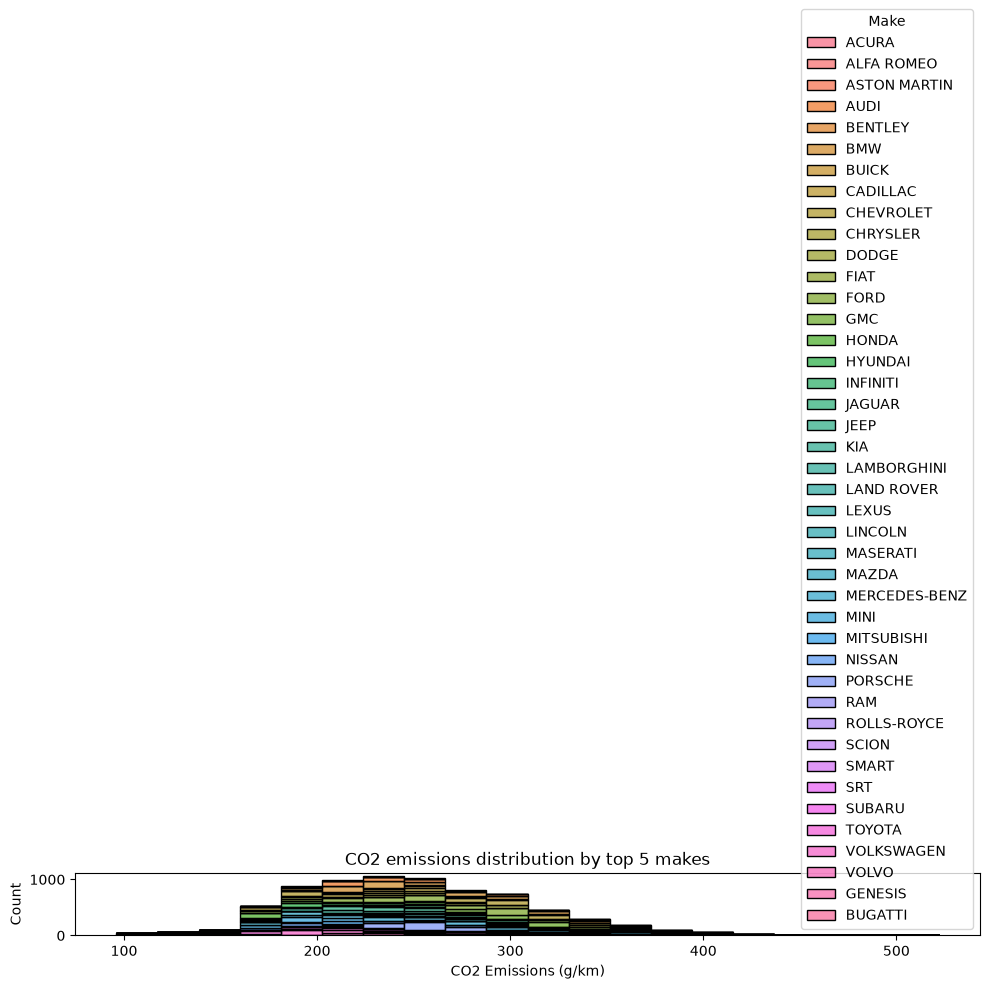

In [7]:
filtered = df[['Make', 'CO2 Emissions(g/km)']]
plt.figure(figsize=(10, 6))
sns.histplot(data=filtered, x='CO2 Emissions(g/km)', hue='Make', multiple='stack', bins=20)
plt.title('CO2 emissions distribution by top 5 makes')
plt.xlabel('CO2 Emissions (g/km)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

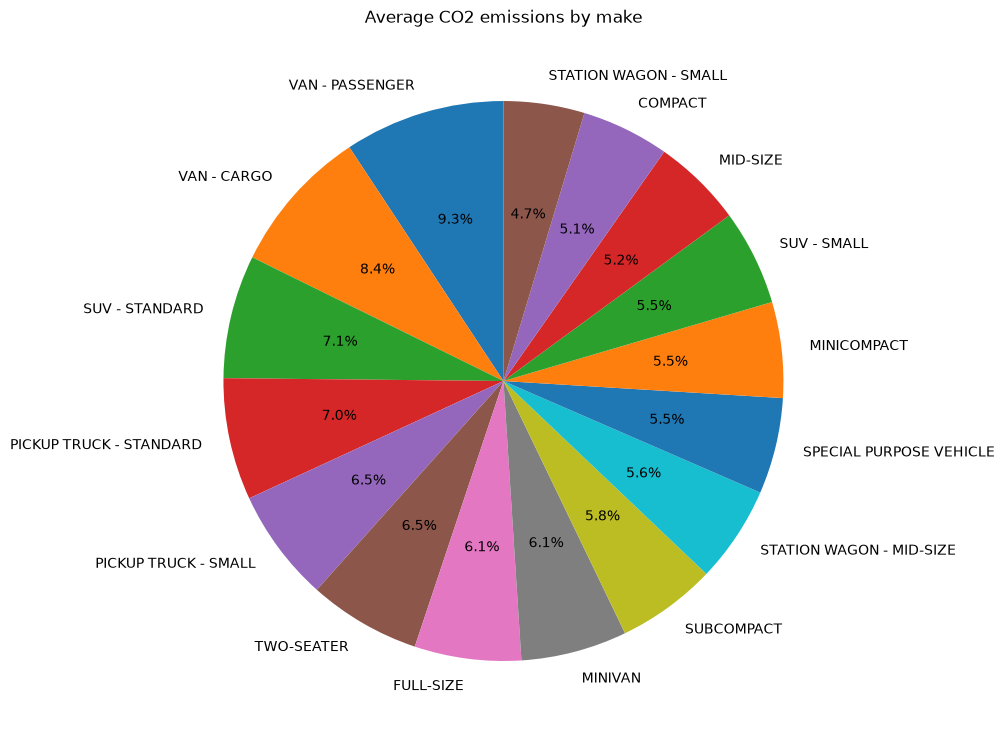

In [ ]:
m_co2=df.groupby('Vehicle Class')['CO2 Emissions(g/km)'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 10))
plt.pie(m_co2.values, labels=m_co2.index, autopct='%1.1f%%', startangle=90)
plt.title('Average CO2 emissions by make')
plt.tight_layout()
plt.show()

/tmp/ipykernel_347277/2389544909.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='High CO2')


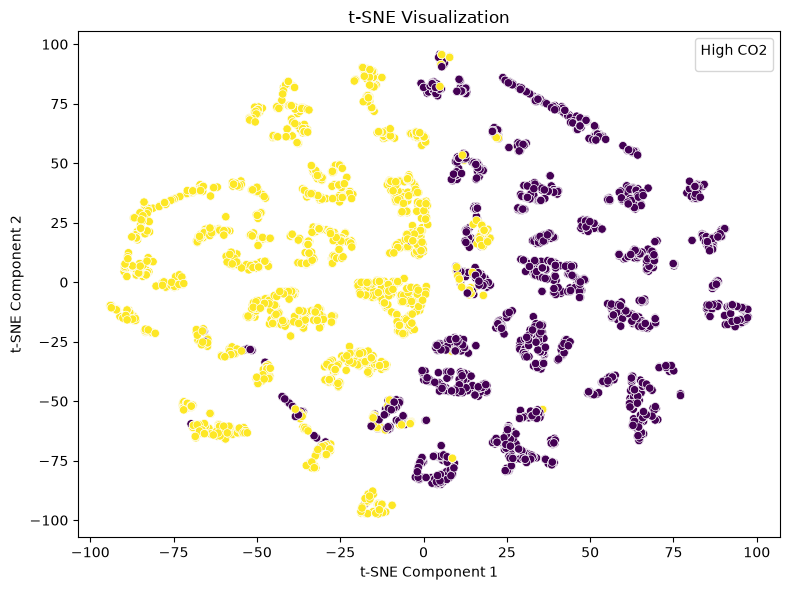

In [ ]:

num_features=df.select_dtypes(include=[np.number]).drop(columns=['CO2 Emissions(g/km)'])
X=num_features.values

median=df['CO2 Emissions(g/km)'].median()
y=(df['CO2 Emissions(g/km)']>=median).astype(int)
model=TSNE(n_components=2)
tsne_data=model.fit_transform(X)

tsne_df=pd.DataFrame({'TSNE_1': tsne_data[:, 0],'TSNE_2': tsne_data[:, 1],'HighEmission': y})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=tsne_df, x='TSNE_1',y='TSNE_2',c=y)
plt.title('t-SNE Visualization')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(title='High CO2')
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

r_df = df.copy()
categorical_cols=['Make','Model','Vehicle Class','Transmission','Fuel Type']
target_col='CO2 Emissions(g/km)'
feature_cols=[column for column in df.columns if column != target_col]
numeric_cols=[column for column in df.columns if column not in categorical_cols + [target_col]]

label_encoders={}
for column in categorical_cols:
    encoder=LabelEncoder()
    r_df[column]=encoder.fit_transform(r_df[column].astype(str))
    label_encoders[column]=encoder

X=r_df[feature_cols]
y=r_df[target_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20)
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

linear_model=LinearRegression()
linear_model.fit(X_train_scaled, y_train)

train_predictions = linear_model.predict(X_train_scaled)
test_predictions = linear_model.predict(X_test_scaled)

def adjusted_r2(y_true, predictions, no_features):
    count=len(y_true)
    r2=r2_score(y_true, predictions)
    return 1-((1-r2)*(count-1)/(count-no_features-1))

def print_metrics(dataset, y_true, predictions, no_features):
    mse=mean_squared_error(y_true, predictions)
    rmse=np.sqrt(mse)
    r2=r2_score(y_true, predictions)
    adjusted=adjusted_r2(y_true, predictions, no_features)
    mae=mean_absolute_error(y_true, predictions)

    print(f'--- {dataset} data ---')
    print(f'MSE: {mse:.4f}')
    print(f'RMSE: {rmse:.4f}')
    print(f'R2 score: {r2:.4f}')
    print(f'Adjusted R2 score: {adjusted:.4f}')
    print(f'MAE: {mae:.4f}')

print_metrics('Training', y_train, train_predictions, X_train.shape[1])
print_metrics('Testing', y_test, test_predictions, X_test.shape[1])

--- Training data ---
MSE: 289.3629
RMSE: 17.0107
R2 score: 0.9167
Adjusted R2 score: 0.9165
MAE: 11.1600
--- Testing data ---
MSE: 284.3916
RMSE: 16.8639
R2 score: 0.9117
Adjusted R2 score: 0.9110
MAE: 11.1163


In [ ]:
for k in [4,6,8,10]:
    pca=PCA(n_components=k)
    Xt=pca.fit_transform(X_train_scaled)
    Xv=pca.transform(X_test_scaled)
    model=LinearRegression()
    model.fit(Xt,y_train)
    train_predictions2 = model.predict(Xt)
    test_predictions2 = model.predict(Xv)

    print_metrics(f'PCA with {k} components', y_train, train_predictions2, k)
    print_metrics(f'PCA with {k} components', y_test, test_predictions2, k)

--- PCA with 4 components data ---
MSE: 303.4560
RMSE: 17.4200
R2 score: 0.9112
Adjusted R2 score: 0.9111
MAE: 11.7220
--- PCA with 4 components data ---
MSE: 313.0644
RMSE: 17.6936
R2 score: 0.9090
Adjusted R2 score: 0.9083
MAE: 11.9652
--- PCA with 6 components data ---
MSE: 300.1203
RMSE: 17.3240
R2 score: 0.9122
Adjusted R2 score: 0.9120
MAE: 11.7285
--- PCA with 6 components data ---
MSE: 306.3858
RMSE: 17.5039
R2 score: 0.9109
Adjusted R2 score: 0.9103
MAE: 11.8785
--- PCA with 8 components data ---
MSE: 287.1135
RMSE: 16.9444
R2 score: 0.9160
Adjusted R2 score: 0.9159
MAE: 11.0028
--- PCA with 8 components data ---
MSE: 297.3493
RMSE: 17.2438
R2 score: 0.9136
Adjusted R2 score: 0.9129
MAE: 11.2114
--- PCA with 10 components data ---
MSE: 286.0103
RMSE: 16.9118
R2 score: 0.9163
Adjusted R2 score: 0.9162
MAE: 10.9731
--- PCA with 10 components data ---
MSE: 295.4047
RMSE: 17.1873
R2 score: 0.9141
Adjusted R2 score: 0.9135
MAE: 11.1799


In [ ]:
X = df.drop(columns=target_col)
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20)

encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
X_train_cat = encoder.fit_transform(X_train[categorical_cols])
X_test_cat = encoder.transform(X_test[categorical_cols])

X_train_num = X_train[numeric_cols].to_numpy()
X_test_num = X_test[numeric_cols].to_numpy()
X_train_ohe = np.hstack([X_train_num, X_train_cat])
X_test_ohe = np.hstack([X_test_num, X_test_cat])
scaler = StandardScaler()
X_train_scaled2=scaler.fit_transform(X_train_ohe)
X_test_scaled2=scaler.transform(X_test_ohe)
linear_model=LinearRegression()
linear_model.fit(X_train_scaled2, y_train)
train_predictions = linear_model.predict(X_train_scaled2)
test_predictions = linear_model.predict(X_test_scaled2)
no_features = X_train_scaled2.shape[1]

print_metrics('One-hot encoded training',y_train,train_predictions,no_features)
print_metrics('One-hot encoded testing',y_test,test_predictions,no_features)

--- One-hot encoded training data ---
MSE: 8.7437
RMSE: 2.9570
R2 score: 0.9975
Adjusted R2 score: 0.9961
MAE: 1.9281
--- One-hot encoded testing data ---
MSE: 28.9036
RMSE: 5.3762
R2 score: 0.9912
Adjusted R2 score: 1.0234
MAE: 3.2140


<!-- X = df.drop(columns=target_col)
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20)

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_cols),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

one_hot_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

one_hot_model.fit(X_train, y_train)

train_predictions = one_hot_model.predict(X_train)
test_predictions = one_hot_model.predict(X_test)

number_of_features = one_hot_model.named_steps[
    'preprocessor'
].get_feature_names_out().shape[0]

print_metrics('One-hot encoded training',y_train,train_predictions,no_features)
print_metrics('One-hot encoded testing',y_test,test_predictions,no_features) -->

In [17]:
for k in [4,6,8,10]:
    pca=PCA(n_components=k)
    Xt=pca.fit_transform(X_train_scaled2)
    Xv=pca.transform(X_test_scaled2)
    model=LinearRegression()
    model.fit(Xt,y_train)
    train_predictions2 = model.predict(Xt)
    test_predictions2 = model.predict(Xv)

    print_metrics(f'PCA with {k} components', y_train, train_predictions2, k)
    print_metrics(f'PCA with {k} components', y_test, test_predictions2, k)

--- PCA with 4 components data ---
MSE: 504.3374
RMSE: 22.4575
R2 score: 0.8543
Adjusted R2 score: 0.8542
MAE: 15.6249
--- PCA with 4 components data ---
MSE: 593.3571
RMSE: 24.3589
R2 score: 0.8187
Adjusted R2 score: 0.8182
MAE: 16.8534
--- PCA with 6 components data ---
MSE: 486.6399
RMSE: 22.0599
R2 score: 0.8594
Adjusted R2 score: 0.8592
MAE: 15.2900
--- PCA with 6 components data ---
MSE: 580.9640
RMSE: 24.1032
R2 score: 0.8225
Adjusted R2 score: 0.8218
MAE: 16.4715
--- PCA with 8 components data ---
MSE: 484.8891
RMSE: 22.0202
R2 score: 0.8599
Adjusted R2 score: 0.8597
MAE: 15.1865
--- PCA with 8 components data ---
MSE: 572.1872
RMSE: 23.9204
R2 score: 0.8252
Adjusted R2 score: 0.8242
MAE: 16.4026
--- PCA with 10 components data ---
MSE: 460.5006
RMSE: 21.4593
R2 score: 0.8669
Adjusted R2 score: 0.8667
MAE: 15.0295
--- PCA with 10 components data ---
MSE: 544.6186
RMSE: 23.3371
R2 score: 0.8336
Adjusted R2 score: 0.8325
MAE: 16.1974


In [ ]:
## (g) L1 and L2 regularization

r_df = df.copy()
for column in categorical_cols:
    r_df[column]=LabelEncoder().fit_transform(
        r_df[column].astype(str)
    )

X_regularized=r_df[feature_cols]
y_regularized=r_df[target_col]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split( X_regularized, y_regularized, test_size=0.20)

r_scaler=StandardScaler()
X_train_reg_scaled=r_scaler.fit_transform(X_train_reg)
X_test_reg_scaled=r_scaler.transform(X_test_reg)
ridge_model=Ridge(alpha=1.0)
lasso_model=Lasso(alpha=0.01, max_iter=100000)
ridge_model.fit(X_train_reg_scaled, y_train_reg)
lasso_model.fit(X_train_reg_scaled, y_train_reg)

def evaluate_regularized_model(name, model):
    train_pred=model.predict(X_train_reg_scaled)
    test_pred=model.predict(X_test_reg_scaled)
    print_metrics(f'{name} training',y_train_reg,train_pred,X_train_reg_scaled.shape[1])
    print_metrics(f'{name} testing',y_test_reg,test_pred,X_test_reg_scaled.shape[1])

evaluate_regularized_model('Ridge (L2)', ridge_model)
evaluate_regularized_model('Lasso (L1)', lasso_model)

--- Ridge (L2) training data ---
MSE: 290.5056
RMSE: 17.0442
R2 score: 0.9146
Adjusted R2 score: 0.9145
MAE: 11.1579
--- Ridge (L2) testing data ---
MSE: 278.4197
RMSE: 16.6859
R2 score: 0.9205
Adjusted R2 score: 0.9199
MAE: 10.7571
--- Lasso (L1) training data ---
MSE: 290.5107
RMSE: 17.0444
R2 score: 0.9146
Adjusted R2 score: 0.9145
MAE: 11.1572
--- Lasso (L1) testing data ---
MSE: 278.5497
RMSE: 16.6898
R2 score: 0.9205
Adjusted R2 score: 0.9199
MAE: 10.7577


In [ ]:
# Part (h): Linear Regression using SGDRegressor
h_df = df.copy()

for column in categorical_cols:
    encoder=LabelEncoder()
    h_df[column]=encoder.fit_transform(h_df[column].astype(str))

X_h = h_df.drop(columns=target_col)
y_h = h_df[target_col]
X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(X_h, y_h,test_size=0.20,random_state=42)
scaler_g = StandardScaler()
X_train_g = scaler_g.fit_transform(X_train_g)
X_test_g = scaler_g.transform(X_test_g)

# SGD linear regression
sgd_model = SGDRegressor()
sgd_model.fit(X_train_g, y_train_g)
train_pred_sgd = sgd_model.predict(X_train_g)
test_pred_sgd = sgd_model.predict(X_test_g)

print_metrics('SGDRegressor training',y_train_g,train_pred_sgd,X_train_g.shape[1])

print_metrics('SGDRegressor testing', y_test_g,test_pred_sgd,X_test_g.shape[1])

--- SGDRegressor training data ---
MSE: 286.1084
RMSE: 16.9147
R2 score: 0.9163
Adjusted R2 score: 0.9162
MAE: 10.9971
--- SGDRegressor testing data ---
MSE: 295.5316
RMSE: 17.1910
R2 score: 0.9141
Adjusted R2 score: 0.9134
MAE: 11.2105
